In [79]:
import pandas as pd
from pathlib import Path
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [80]:
dataset_path = Path('../dataset')
df = pd.read_csv(dataset_path / 'train.csv')
df.date = pd.to_datetime(df.date)
df.head()

,user_id,recipe_id,date,rating
0,1293707,150898,2011-01-04,5
1,1293707,25360,2011-01-04,5
2,1293707,99564,2011-01-06,4
3,1293707,70758,2011-01-09,5
4,1293707,115110,2011-01-26,5


In [81]:
df.describe()

,user_id,recipe_id,date,rating
count,1.571080e+05,157108.000000,157108,157108.000000
mean,7.089527e+06,90281.169145,2007-07-23 01:53:33.758688,4.660094
min,1.533000e+03,62.000000,2001-04-18 00:00:00,0.000000
25%,9.757900e+04,32614.000000,2006-01-10 00:00:00,5.000000
50%,2.159560e+05,69484.000000,2007-09-01 00:00:00,5.000000
75%,4.379730e+05,119544.000000,2008-12-31 00:00:00,5.000000
max,2.001453e+09,496591.000000,2018-05-14 00:00:00,5.000000
std,1.130750e+08,76689.736519,NaN,0.833243


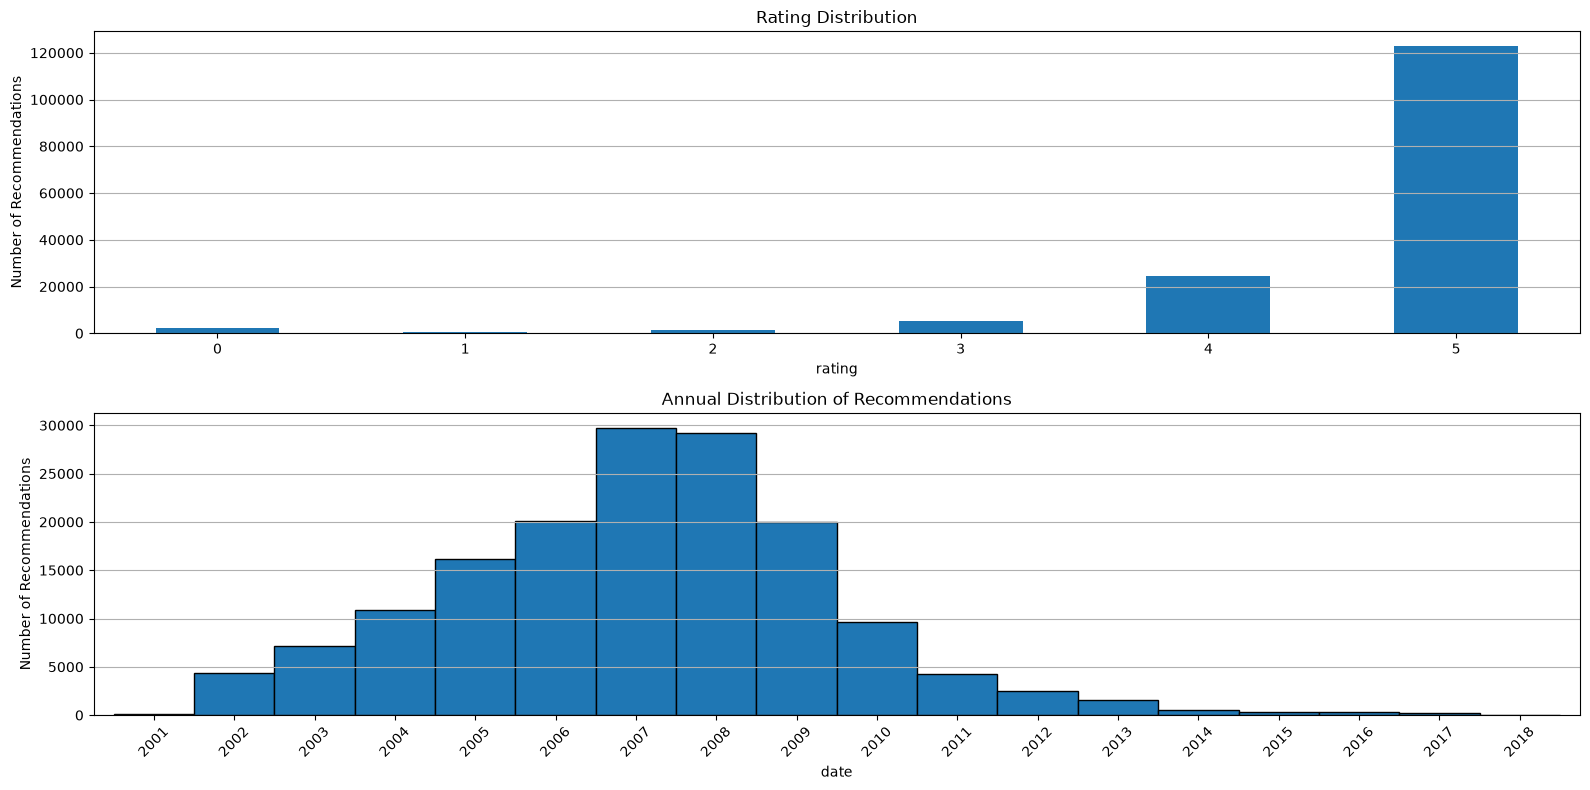

In [82]:
fig, (general, anual) = plt.subplots(figsize=(16, 8), nrows=2, ncols=1)

general.set_ylabel("Number of Recommendations")
general.set_title("Rating Distribution")

df["rating"].value_counts().sort_index().plot(
    kind="bar", ax=general, rot=0
)
general.grid(True, axis="y", which="both")

anual.set_ylabel("Number of Recommendations")
anual.set_title("Annual Distribution of Recommendations")

df["date"].dt.to_period("Y").value_counts().sort_index().plot(
    kind="bar", ax=anual, rot=45, width=1.0, edgecolor="black"
)

anual.grid(True, axis="y", which="both")

plt.tight_layout()

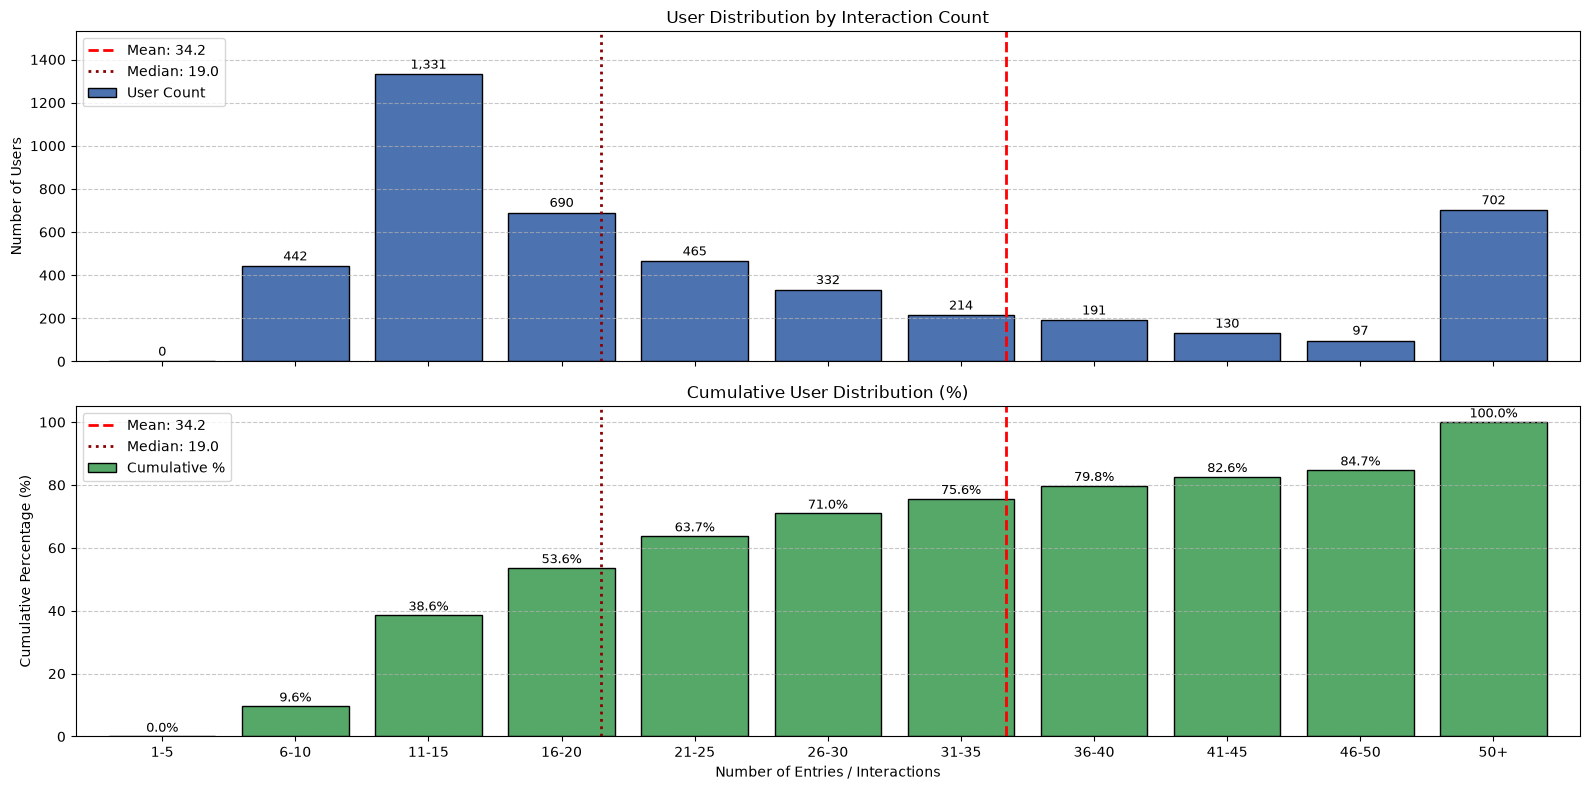

In [83]:
user_counts = df["user_id"].value_counts()

mean_val = user_counts.mean()
median_val = user_counts.median()

hasta = 50
intervalo = 5

bins = [i for i in range(0, hasta + 1, intervalo)] + [np.inf]
labels = [f"{i}-{i+4}" for i in range(1, hasta - 1, intervalo)] + [f"{hasta}+"]

binned_users = pd.cut(user_counts, bins=bins, labels=labels, right=True)
dist = binned_users.value_counts(sort=False)
cum_dist = dist.cumsum()
cum_pct = (cum_dist / dist.sum()) * 100

fig, (densidad, acomulada) = plt.subplots(
    nrows=2, ncols=1, figsize=(16, 8), sharex=True
)

dist.plot(
    kind="bar",
    ax=densidad,
    width=0.8,
    edgecolor="black",
    color="#4C72B0",
    label="User Count",
)
densidad.set_title("User Distribution by Interaction Count")
densidad.set_ylabel("Number of Users")
densidad.set_ylim(0, dist.max() * 1.15)
densidad.grid(axis="y", linestyle="--", alpha=0.7)

for idx, val in enumerate(dist):
    densidad.text(
        idx, val + (dist.max() * 0.02), f"{val:,}", ha="center", fontsize=9
    )

cum_pct.plot(
    kind="bar",
    ax=acomulada,
    width=0.8,
    edgecolor="black",
    color="#55A868",
    rot=0,
    label="Cumulative %",
)
acomulada.set_title("Cumulative User Distribution (%)")
acomulada.set_xlabel("Number of Entries / Interactions")
acomulada.set_ylabel("Cumulative Percentage (%)")
acomulada.set_ylim(0, 105)
acomulada.grid(axis="y", linestyle="--", alpha=0.7)

for idx, val in enumerate(cum_pct):
    acomulada.text(idx, val + 1.5, f"{val:.1f}%", ha="center", fontsize=9)


def value_to_cat_x(val):
    if val <= hasta:
        return (val / intervalo) - 0.5
    return float(len(labels) - 1)


mean_x = value_to_cat_x(mean_val)
median_x = value_to_cat_x(median_val)

for ax in (densidad, acomulada):
    ax.axvline(
        mean_x,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mean: {mean_val:.1f}",
    )
    ax.axvline(
        median_x,
        color="darkred",
        linestyle=":",
        linewidth=2,
        label=f"Median: {median_val:.1f}",
    )
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

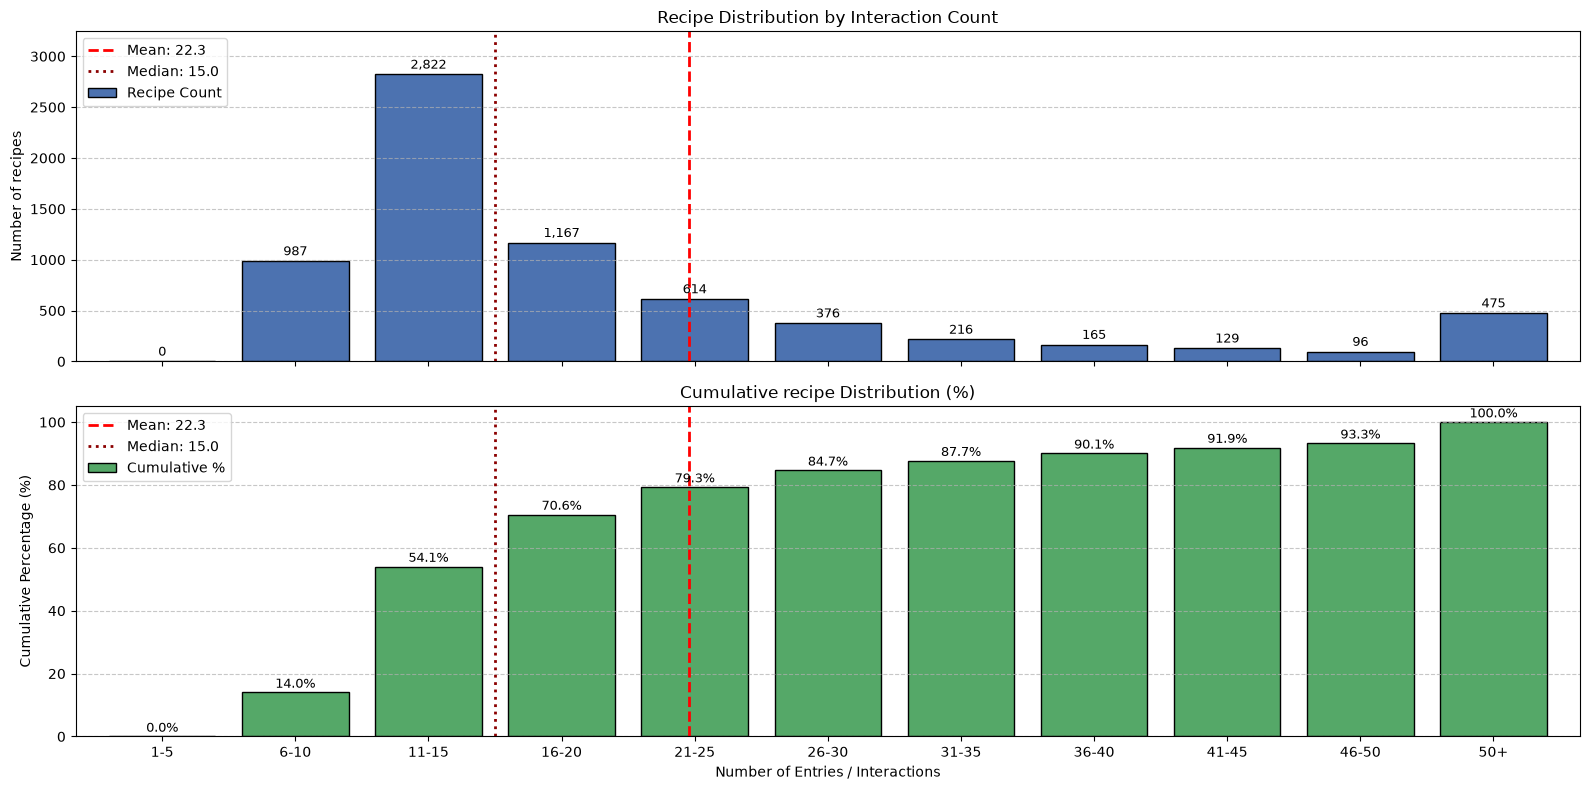

In [84]:
recipe_counts = df["recipe_id"].value_counts()

mean_val = recipe_counts.mean()
median_val = recipe_counts.median()

hasta = 50
intervalo = 5

bins = [i for i in range(0, hasta + 1, intervalo)] + [np.inf]
labels = [f"{i}-{i+4}" for i in range(1, hasta - 1, intervalo)] + [f"{hasta}+"]

binned_recipes = pd.cut(recipe_counts, bins=bins, labels=labels, right=True)
dist = binned_recipes.value_counts(sort=False)
cum_dist = dist.cumsum()
cum_pct = (cum_dist / dist.sum()) * 100

fig, (densidad, acomulada) = plt.subplots(
    nrows=2, ncols=1, figsize=(16, 8), sharex=True
)

dist.plot(
    kind="bar",
    ax=densidad,
    width=0.8,
    edgecolor="black",
    color="#4C72B0",
    label="Recipe Count",
)
densidad.set_title("Recipe Distribution by Interaction Count")
densidad.set_ylabel("Number of recipes")
densidad.set_ylim(0, dist.max() * 1.15)
densidad.grid(axis="y", linestyle="--", alpha=0.7)

for idx, val in enumerate(dist):
    densidad.text(
        idx, val + (dist.max() * 0.02), f"{val:,}", ha="center", fontsize=9
    )

cum_pct.plot(
    kind="bar",
    ax=acomulada,
    width=0.8,
    edgecolor="black",
    color="#55A868",
    rot=0,
    label="Cumulative %",
)
acomulada.set_title("Cumulative recipe Distribution (%)")
acomulada.set_xlabel("Number of Entries / Interactions")
acomulada.set_ylabel("Cumulative Percentage (%)")
acomulada.set_ylim(0, 105)
acomulada.grid(axis="y", linestyle="--", alpha=0.7)

for idx, val in enumerate(cum_pct):
    acomulada.text(idx, val + 1.5, f"{val:.1f}%", ha="center", fontsize=9)


def value_to_cat_x(val):
    if val <= hasta:
        return (val / intervalo) - 0.5
    return float(len(labels) - 1)


mean_x = value_to_cat_x(mean_val)
median_x = value_to_cat_x(median_val)

for ax in (densidad, acomulada):
    ax.axvline(
        mean_x,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mean: {mean_val:.1f}",
    )
    ax.axvline(
        median_x,
        color="darkred",
        linestyle=":",
        linewidth=2,
        label=f"Median: {median_val:.1f}",
    )
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

In [ ]:
top_k = 5
metadata = pd.read_csv(dataset_path / 'item_metadata.csv')

## Top k mas populares

In [111]:
top_k_most_popular = df.recipe_id.value_counts().index[:top_k]
metadata[metadata['id'].isin(top_k_most_popular)]

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
24,whatever floats your boat brownies,32204,35,37305,2002-06-25,"['60-minutes-or-less', 'time-to-make', 'course...","[390.7, 30.0, 161.0, 7.0, 12.0, 50.0, 17.0]",14,"['preheat oven to 350f', 'grease an 8 inch squ...","these are absolutely the chewiest, moistest, f...","['butter', 'unsweetened cocoa', 'sugar', 'eggs...",14
1911,creamy cajun chicken pasta,39087,25,30534,2002-09-02,"['30-minutes-or-less', 'time-to-make', 'course...","[719.1, 63.0, 12.0, 34.0, 78.0, 120.0, 15.0]",4,['place chicken and cajun seasoning in a bowl ...,n'awlin's style of chicken with an updated alf...,"['boneless skinless chicken breast halves', 'l...",12
2115,crock pot chicken with black beans cream cheese,89204,243,137839,2004-04-16,"['time-to-make', 'course', 'main-ingredient', ...","[679.2, 53.0, 39.0, 38.0, 91.0, 75.0, 16.0]",5,"['take 4-5 frozen , yes , frozen , boneless ch...",i love this crock-pot chicken recipe for two r...,"['boneless chicken breasts', 'black beans', 'c...",5
3612,jo mama s world famous spaghetti,22782,80,25455,2002-03-17,"['weeknight', 'time-to-make', 'course', 'main-...","[555.9, 40.0, 45.0, 85.0, 59.0, 45.0, 16.0]",10,"['in large , heavy stockpot , brown italian sa...",my kids will give up a steak dinner for this s...,"['italian sausage', 'onion', 'garlic cloves', ...",16
6557,to die for crock pot roast,27208,545,28201,2002-05-03,"['weeknight', 'time-to-make', 'course', 'main-...","[295.2, 14.0, 0.0, 15.0, 99.0, 19.0, 0.0]",7,"['place beef roast in crock pot', 'mix the dri...","amazing flavor, and so simple! no salt needed ...","['beef roast', 'brown gravy mix', 'dried itali...",5


## Top K best rated

In [108]:
top_k_best_rated = df.groupby("recipe_id")["rating"].mean()[:top_k].index
metadata[metadata['id'].isin(top_k_best_rated)]

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
164,amish friendship bread and starter,153,70,1540,1999-09-06,"['time-to-make', 'course', 'cuisine', 'prepara...","[615.9, 32.0, 260.0, 15.0, 16.0, 19.0, 33.0]",19,"['place one cup each sugar , milk , and flour ...",many recipes have been posted for the amish br...,"['sugar', 'milk', 'flour', 'oil', 'eggs', 'van...",12
771,black bean corn and tomato salad,62,25,1570,1999-08-19,"['30-minutes-or-less', 'time-to-make', 'course...","[407.8, 23.0, 17.0, 0.0, 34.0, 11.0, 18.0]",4,"['in a bowl whisk together lemon juice , oil ,...","this is easy, delicious, colorful, delicious, ...","['fresh lemon juice', 'olive oil', 'black bean...",9
1493,chinese hot and sour pork soup,198,40,1545,1999-09-18,"['60-minutes-or-less', 'time-to-make', 'course...","[368.7, 20.0, 41.0, 60.0, 63.0, 14.0, 10.0]",11,"['bring stock to a simmer', 'add soy sauce , p...",edited recipe from other viewers recomendations,"['chicken stock', 'lean pork', 'garlic and red...",17
1682,classic cream scones,192,85,1609,1999-08-13,"['weeknight', 'time-to-make', 'course', 'prepa...","[168.2, 12.0, 28.0, 3.0, 5.0, 24.0, 7.0]",20,"['preheat oven to 425f', 'lightly butter a bak...",you're best off describing scones to a german ...,"['all-purpose flour', 'granulated sugar', 'bak...",9
3883,lee s hot crab dip,246,45,25843,1999-09-01,"['60-minutes-or-less', 'time-to-make', 'course...","[180.7, 23.0, 7.0, 16.0, 16.0, 40.0, 1.0]",8,"['remove cartilage from crab meat', 'in a larg...",lee's hot crab dip,"['crabmeat', 'cream cheese', 'sour cream', 'ma...",10
